## Topic 6: Performance Metrics in Machine Learning

## Q1. Dataset Loading

Load the Iris Dataset using Scikit-learn and display the first 10 records, dataset shape, feature names, and target classes.

In [1]:

import pandas as pd
from sklearn.datasets import load_iris


iris = load_iris()


df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df["target"] = iris.target

In [2]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [3]:

df.shape

(150, 5)

In [4]:

iris.feature_names


['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

In [5]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

## Q2. Exploratory Data Analysis (EDA)

Perform Exploratory Data Analysis (EDA) by:

    Checking data types
    Identifying missing values
    Displaying statistical summary
    Displaying the class distribution

In [6]:
df.dtypes

sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
target                 int64
dtype: object

In [7]:
df.isna().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

In [8]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [9]:
df["target"].value_counts().sort_index()

target
0    50
1    50
2    50
Name: count, dtype: int64

## Q3. Data Preprocessing

Prepare the dataset by:

    Separating features (X) and target (y)
    Splitting the data into 80% training and 20% testing sets using random_state=42

In [11]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)


Training Features Shape: (120, 4)
Testing Features Shape: (30, 4)
Training Target Shape: (120,)
Testing Target Shape: (30,)


## Q4. Model Training

Train a Logistic Regression classifier using the training dataset and make predictions on the testing dataset.

In [13]:

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Actual value")
print(y_test.values)

print("\nPredicted value")
print(y_pred)


Actual value
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]

Predicted value
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]


## Q5. Confusion Matrix

Generate the Confusion Matrix and explain the meaning of:

    True Positive (TP)
    True Negative (TN)
    False Positive (FP)
    False Negative (FN)

[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


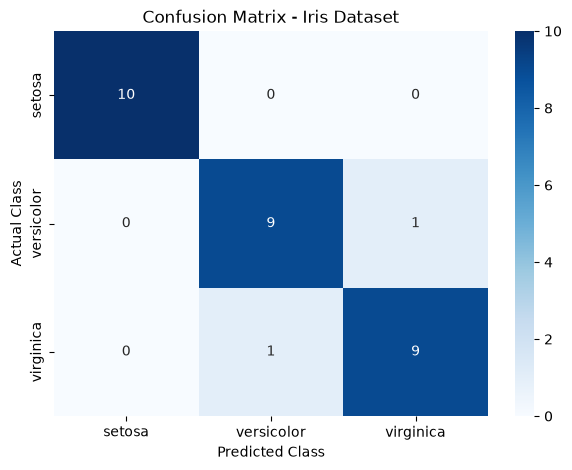

In [14]:

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

print(cm)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix - Iris Dataset")
plt.show()


## Q6. Classification Metrics

Calculate and interpret the following metrics:

    Accuracy
    Precision
    Recall
    F1-Score

In [15]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average="weighted"
)

recall = recall_score(
    y_test, y_pred, average="weighted"
)

f1 = f1_score(
    y_test, y_pred, average="weighted"
)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-Score:", f1)


Accuracy: 0.9333333333333333
Precision: 0.9333333333333333
Recall: 0.9333333333333333
F1-Score: 0.9333333333333333


## Q7. Classification Report

Generate the Classification Report and explain the significance of Precision, Recall, F1-Score, and Support for each class.

In [16]:
from sklearn.metrics import classification_report
report = classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
)
print(report)

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



## Q8. Visualization

Create the following visualizations:

    Confusion Matrix Heatmap
    Bar Chart comparing Accuracy, Precision, Recall, and F1-Score
    Write your observations.

**1 Confusion Matrix Heatmap**

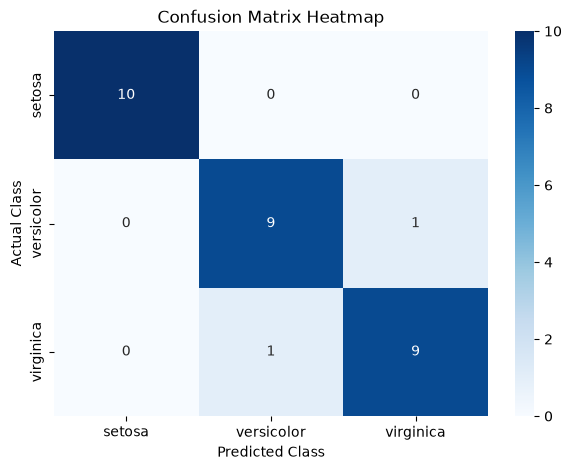

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("Confusion Matrix Heatmap")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

**Observation:** Higher values along the main diagonal indicate correct predictions. Values outside the diagonal indicate misclassified samples.

**2 Bar Chart Comparing Classification Metrics**

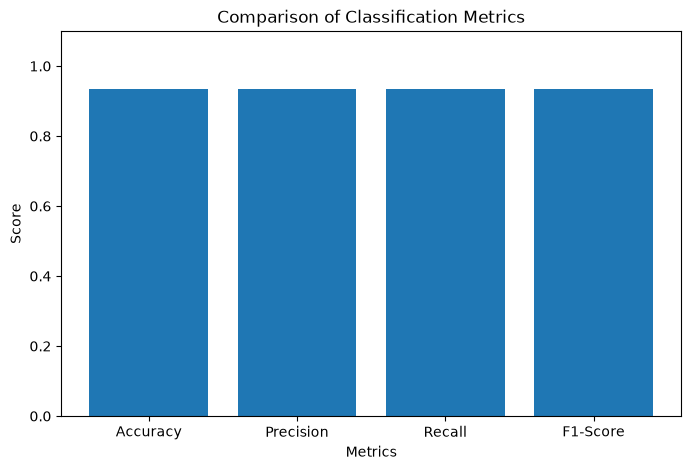

Classification Metrics:
Accuracy: 0.9333
Precision: 0.9333
Recall: 0.9333
F1-Score: 0.9333


In [18]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(
        y_test, y_pred, average="weighted"
    ),
    "Recall": recall_score(
        y_test, y_pred, average="weighted"
    ),
    "F1-Score": f1_score(
        y_test, y_pred, average="weighted"
    )
}

plt.figure(figsize=(8, 5))

plt.bar(metrics.keys(), metrics.values())

plt.title("Comparison of Classification Metrics")
plt.xlabel("Metrics")
plt.ylabel("Score")
plt.ylim(0, 1.1)

plt.show()

print("Classification Metrics:")
for name, score in metrics.items():
    print(f"{name}: {score:.4f}")


**Observation:** Higher bars indicate better scores. Similar scores suggest balanced performance across the evaluation metrics, although class-level results should also be checked.

## Q9. Model Comparison

Train another classification model (e.g., Decision Tree or K-Nearest Neighbors) on the same dataset and compare its performance metrics with Logistic Regression.

In [19]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

log_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

log_model.fit(X_train, y_train)
log_pred = log_model.predict(X_test)

tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train, y_train)

tree_pred = tree_model.predict(X_test)

def evaluate_model(name, actual, predicted):
    return {
        "Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(
            actual, predicted, average="weighted"
        ),
        "Recall": recall_score(
            actual, predicted, average="weighted"
        ),
        "F1-Score": f1_score(
            actual, predicted, average="weighted"
        )
    }

results = pd.DataFrame([
    evaluate_model("Logistic Regression", y_test, log_pred),
    evaluate_model("Decision Tree", y_test, tree_pred)
])
print(results.to_string(index=False))


              Model  Accuracy  Precision   Recall  F1-Score
Logistic Regression  0.933333   0.933333 0.933333  0.933333
      Decision Tree  0.933333   0.933333 0.933333  0.933333


## Q10. Conclusion

Write a short report that includes:

    Which evaluation metric is most suitable for this dataset and why.
    Compare the performance of both models.
    Mention two real-world applications where performance metrics are important for evaluating machine learning models.

## Conclusion: Performance Metrics in Machine Learning

**1. Most Suitable Evaluation Metric**

Accuracy is a suitable primary metric for the Iris dataset because the three classes have equal numbers of samples. It measures the proportion of correctly classified samples. However, precision, recall, and F1-score are also useful for understanding class-level performance.

**2. Comparison of Both Models**

Logistic Regression and Decision Tree Classifier were trained and evaluated using the same testing dataset. Their accuracy, precision, recall, and F1-score were compared. The model with better test performance can be preferred based on the evaluation results.

**3. Importance of Performance Metrics**

Performance metrics help evaluate model reliability, identify classification errors, and compare different machine learning algorithms. They help determine whether a model is suitable for its intended application.

**4. Real-World Applications**

- **Medical diagnosis:** Performance metrics help assess how accurately a model identifies diseases and reduce the risk of incorrect predictions.
- **Fraud detection:** Precision and recall help evaluate how effectively a model identifies fraudulent transactions while managing false alarms.

**Final Conclusion**

Performance metrics are essential for evaluating and comparing machine learning models. For the balanced Iris dataset, accuracy is a useful overall measure, while precision, recall, and F1-score provide additional information about classification performance. The final model should be selected based on its measured results and intended use.